In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
import pandas as pd
import pickle
import time
import os
import matplotlib

tau= 24 mean= 7.822404266132657e-07 std= 7.597787673653293e-08


C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


tau= 40 mean= 4.4219354002664495e-07 std= 4.635446792918087e-08


C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


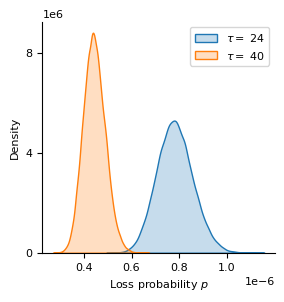

In [14]:
def find_tot_plasmids(y1,y2,max_size):
    y1[0]+=y1[1]   #because of plasmid shedding y[1] may have a nonzero value, we transfer this to y[0].
    y2[0]+=y2[1]
    y1[1]=y1[0]
    y2[1]=y2[0]
    y_tot1 = np.dot(np.arange(1,max_size),y1[1:max_size])
    y_tot2 = np.dot(np.arange(1,max_size),y2[1:max_size])            
    return y_tot1,y_tot2

def parse_file(filename):
    with open(filename, 'r', encoding='utf-8') as f:
        lines = f.readlines()
    line = lines[0].split()
    return line[2]

alpha = 1
beta = 1

#### original sims#######
tau_vec = [24,40]

fig = plt.figure(figsize=(3,3))
plt.rc('font', size=8)
ax = fig.add_subplot(111)
means_p = np.zeros(3)
std_p = np.zeros(3)
kk=0

a_vec=np.zeros_like(tau_vec)
b_vec=np.zeros_like(tau_vec)
for tau in tau_vec:
    if tau==24:
        comps = ['05','07','08','09','10','11','14']
        repeats = ['1','2','3','4','5','6','7','8','9','10','11','12','13','14','15']    
    elif tau==40:
        comps = ['04','05','06','07','08','10']
        repeats = ['1','2','3','4','5','6','7','8','9','10','11','12','13','14','15']    
    
    loss =[]
    for i in comps:
        for j in repeats:
            filename = './realistic/orig/tau'+str(tau)+'_collect/'+str(i)+'/'+str(j)+'/out.dat'
            file_size = os.path.getsize(filename)
            if file_size>0:
                dat = float(parse_file(filename))
                loss = np.append(loss,[dat]) 

    obs = 1./loss
    n = len(obs)
    sum_obs = np.sum(obs)-n 
    a = alpha+n
    b= beta+sum_obs
    a_vec[kk] = a
    b_vec[kk] = b
    
    mean=a/(a+b)
    std=np.sqrt(a*b/((a+b+1)*(a+b)**2))
    means_p[kk] =mean
    std_p[kk] =std
    samp = np.random.beta(a,b,100000)
    print('tau=',tau,'mean=',mean,'std=',std)
    sns.kdeplot(samp,ax=ax,fill='True',label=r'$\tau=$ %d' %(tau))
    ax.set_xlabel(r'Loss probability $p$')
    ax.set_yticks([0,4e6,8e6])
    ax.set_xticks([0.4e-6,0.6e-6,0.8e-6,1e-6])
    sns.despine()
    kk+=1
plt.legend()

C:\Users\Jayson Cortez\AppData\Local\Temp\ipykernel_3040\3591915676.py:21: RuntimeWarning: overflow encountered in scalar multiply
  std=np.sqrt(a*b/((a+b+1)*(a+b)**2))
C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


tau= 24 mean= 1.7677105166454273e-06 std= 1.09393169442468


C:\Users\Jayson Cortez\AppData\Local\Temp\ipykernel_3040\3591915676.py:21: RuntimeWarning: overflow encountered in scalar multiply
  std=np.sqrt(a*b/((a+b+1)*(a+b)**2))
C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


tau= 40 mean= 1.0733620209419116e-07 std= 0.5064349300975715


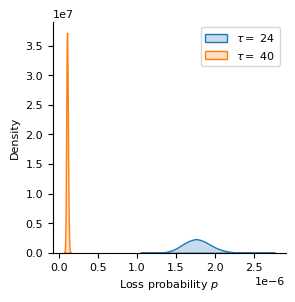

In [10]:
#### match copy numbers ######

fig = plt.figure(figsize=(3,3))
plt.rc('font', size=8)
ax = fig.add_subplot(111)
kk=0
a_vec_m=np.zeros_like(tau_vec)
b_vec_m=np.zeros_like(tau_vec)
for tau in tau_vec: 
    loss =[]
    filename = './realistic/matched/tau'+str(tau)+'_all_loss.csv'
    obs = pd.read_csv(filename)['generations'].values.astype(int)
    n=len(obs)
    sum_obs = np.sum(obs)-n 
    a = alpha+n
    b= beta+sum_obs
    a_vec_m[kk] = a
    b_vec_m[kk] = b
    
    mean=a/(a+b)
    std=np.sqrt(a*b/((a+b+1)*(a+b)**2))
    means_p[kk] =mean
    std_p[kk] =std
    samp = np.random.beta(a,b,100000)
    print('tau=',tau,'mean=',mean,'std=',std)
    sns.kdeplot(samp,ax=ax,fill='True',label=r'$\tau=$ %d' %(tau))
    ax.set_xlabel(r'Loss probability $p$')
    #ax.set_yticks([0,4e6,8e6])
    #ax.set_xticks([0.4e-6,0.6e-6,0.8e-6,1e-6])
    sns.despine()
    kk+=1
plt.legend()

In [23]:
import numpy as np
from scipy.stats import beta

# --------------------------------------------------
# 1. Beta posterior parameters
# Rows: tau = 24, 40 min
# Columns: High (H), Low (L) copy number
# --------------------------------------------------

a = np.array([
    [106, 101],
    [101,  91]
], dtype=float)

b = np.array([
    [135508104,  57135951],
    [940968538, 205792151]
], dtype=float)

# --------------------------------------------------
# 2. Posterior sampling
# --------------------------------------------------

N = 1000000
rng = np.random.default_rng(12345)

# Independent Beta draws for the four conditions
p = rng.beta(a, b, size=(N, 2, 2))

# p[:, 0, 0] = p_24,H
# p[:, 0, 1] = p_24,L
# p[:, 1, 0] = p_40,H
# p[:, 1, 1] = p_40,L

# --------------------------------------------------
# 3. Calculate fold changes for every posterior draw
# --------------------------------------------------

R_time_H = p[:, 0, 0] / p[:, 1, 0]
R_time_L = p[:, 0, 1] / p[:, 1, 1]

R_copy_24 = p[:, 0, 1] / p[:, 0, 0]
R_copy_40 = p[:, 1, 1] / p[:, 1, 0]

# Interaction ratio
R_int = R_time_H / R_time_L

# Equivalent definition: copy-number effects
R_int_check = R_copy_40 / R_copy_24

assert np.allclose(R_int, R_int_check)

# --------------------------------------------------
# 4. Summarize posterior distributions
# --------------------------------------------------

def summarize(x):
    median = np.median(x)
    lower, upper = np.quantile(x, [0.025, 0.975])
    return median, lower, upper

results = {
    "Generation time, high copy": R_time_H,
    "Generation time, low copy": R_time_L,
    "Copy number, tau=24": R_copy_24,
    "Copy number, tau=40": R_copy_40,
    "Interaction ratio": R_int
}

print("Posterior summaries")
print("-" * 92)
print(f"{'Effect':<30} {'Mean':>12} {'Median':>12} "
      f"{'2.5%':>12} {'97.5%':>12}")
print("-" * 92)

for name, draws in results.items():
    mean = np.mean(draws)
    median, lower, upper = summarize(draws)
    print(f"{name:<30} {mean:12.4f} {median:12.4f} "
          f"{lower:12.4f} {upper:12.4f}")

# Posterior probability of interaction > 1
prob_interaction = np.mean(R_int > 1)

print("-" * 78)
print(f"P(R_int > 1 | data) = {prob_interaction:.6f}")

# --------------------------------------------------
# 5. Plug-in estimate using posterior mean probabilities
# --------------------------------------------------

p_mean = a / (a + b)

R_plugin = (
    (p_mean[0, 0] / p_mean[1, 0])
    / (p_mean[0, 1] / p_mean[1, 1])
)

print(f"\nInteraction ratio using posterior mean probabilities: "
      f"{R_plugin:.4f}")

# Posterior means of the four loss probabilities
print("\nPosterior mean loss probabilities:")
print(p_mean)


Posterior summaries
--------------------------------------------------------------------------------------------
Effect                                 Mean       Median         2.5%        97.5%
--------------------------------------------------------------------------------------------
Generation time, high copy           7.3606       7.2895       5.5482       9.5845
Generation time, low copy            4.0417       3.9989       3.0105       5.3159
Copy number, tau=24                  2.2811       2.2593       1.7183       2.9682
Copy number, tau=40                  4.1608       4.1184       3.0955       5.4662
Interaction ratio                    1.8599       1.8228       1.2276       2.7041
------------------------------------------------------------------------------
P(R_int > 1 | data) = 0.998562

Interaction ratio using posterior mean probabilities: 1.8230

Posterior mean loss probabilities:
[[7.82240427e-07 1.76771052e-06]
 [1.07336202e-07 4.42193540e-07]]
